# 1. Contexto do Problema e Dicionário de Dados

## Origem e Objetivo de Negócio
O conjunto de dados utilizado é o **Heart Failure Prediction Dataset** (disponível no Kaggle em `fedesoriano/heart-failure-prediction`), composto por **918 registros clínicos** consolidados a partir de cinco bases cardiológicas internacionais (Cleveland, Hungarian, Switzerland, Long Beach VA e Stalog).

As doenças cardiovasculares representam a principal causa de óbito global. O **objetivo de negócio** deste projeto é construir um sistema de triagem preditiva baseado em **Redes Neurais Artificiais (`MLPClassifier`)** capaz de estimar a probabilidade de um paciente apresentar doença cardíaca a partir de exames clínicos e laboratoriais de rotina. A predição auxilia equipes médicas na priorização de atendimentos especializados e intervenções preventivas.

## Dicionário de Dados

| Coluna | Tipo | Papel | Significado Prático |
| :--- | :--- | :--- | :--- |
| `Age` | Numérica (`int`) | Feature | Idade do paciente em anos completos |
| `Sex` | Categórica (`str`) | Feature | Sexo biológico do paciente (`M` = Masculino, `F` = Feminino) |
| `ChestPainType` | Categórica (`str`) | Feature | Tipo de dor torácica (`TA` = Angina Típica, `ATA` = Angina Atípica, `NAP` = Dor Não-Anginosa, `ASY` = Assintomática) |
| `RestingBP` | Numérica (`int`) | Feature | Pressão arterial em repouso na admissão (em mm Hg) |
| `Cholesterol` | Numérica (`int`) | Feature | Colesterol sérico total (em mg/dl) |
| `FastingBS` | Numérica (`int`) | Feature | Glicemia em jejum maior que 120 mg/dl (`1` = Verdadeiro, `0` = Falso) |
| `RestingECG` | Categórica (`str`) | Feature | Resultado do eletrocardiograma em repouso (`Normal`, `ST` = anormalidade de onda ST-T, `LVH` = hipertrofia ventricular esquerda) |
| `MaxHR` | Numérica (`int`) | Feature | Frequência cardíaca máxima atingida durante teste ergométrico (bpm) |
| `ExerciseAngina` | Categórica (`str`) | Feature | Angina induzida por exercício físico (`Y` = Sim, `N` = Não) |
| `Oldpeak` | Numérica (`float`) | Feature | Depressão do segmento ST induzida pelo exercício em relação ao repouso |
| `ST_Slope` | Categórica (`str`) | Feature | Inclinação do segmento ST no pico do exercício (`Up` = Ascendente, `Flat` = Plana, `Down` = Descendente) |
| `HeartDisease` | Binária (`int`) | **Target** | Diagnóstico alvo (`1` = Presença de doença cardíaca, `0` = Normal) |

# 2. Análise Exploratória Resumida (EDA)

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid', palette='muted')

df = pd.read_csv('../data/dataset.csv')

print(f'Dimensionalidade do dataset (linhas, colunas): {df.shape}')
print('\nContagem de valores ausentes por coluna:')
print(df.isnull().sum())

df.head()

Dimensionalidade do dataset (linhas, colunas): (918, 12)

Contagem de valores ausentes por coluna:
Age               0
Sex               0
ChestPainType     0
RestingBP         0
Cholesterol       0
FastingBS         0
RestingECG        0
MaxHR             0
ExerciseAngina    0
Oldpeak           0
ST_Slope          0
HeartDisease      0
dtype: int64


,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


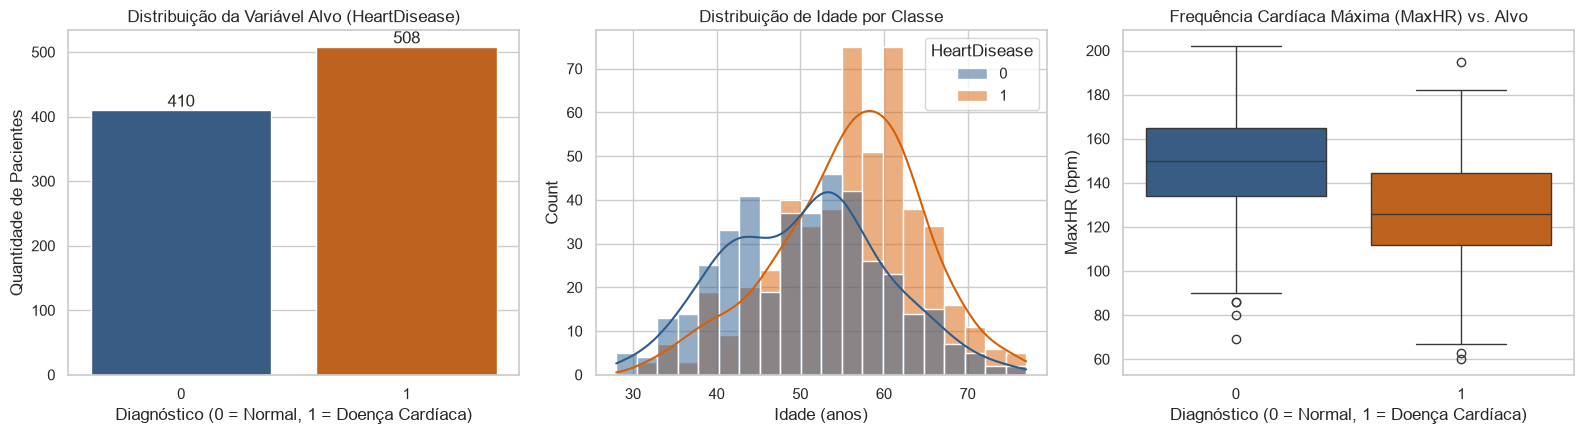

In [2]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

# 1. Balanceamento da variável alvo
sns.countplot(data=df, x='HeartDisease', hue='HeartDisease', palette=['#2b5c8f', '#d95f02'], legend=False, ax=axes[0])
axes[0].set_title('Distribuição da Variável Alvo (HeartDisease)')
axes[0].set_xlabel('Diagnóstico (0 = Normal, 1 = Doença Cardíaca)')
axes[0].set_ylabel('Quantidade de Pacientes')
for container in axes[0].containers:
    axes[0].bar_label(container)

# 2. Distribuição de Idade por Diagnóstico (Histograma)
sns.histplot(data=df, x='Age', hue='HeartDisease', kde=True, bins=20, palette=['#2b5c8f', '#d95f02'], ax=axes[1])
axes[1].set_title('Distribuição de Idade por Classe')
axes[1].set_xlabel('Idade (anos)')

# 3. Boxplot de Frequência Cardíaca Máxima por Diagnóstico
sns.boxplot(data=df, x='HeartDisease', y='MaxHR', hue='HeartDisease', palette=['#2b5c8f', '#d95f02'], legend=False, ax=axes[2])
axes[2].set_title('Frequência Cardíaca Máxima (MaxHR) vs. Alvo')
axes[2].set_xlabel('Diagnóstico (0 = Normal, 1 = Doença Cardíaca)')
axes[2].set_ylabel('MaxHR (bpm)')

plt.tight_layout()
plt.show()

# 3. Construção do Pipeline Scikit-Learn

In [3]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.neural_network import MLPClassifier

X = df.drop(columns=['HeartDisease'])
y = df['HeartDisease']

colunas_numericas = ['Age', 'RestingBP', 'Cholesterol', 'FastingBS', 'MaxHR', 'Oldpeak']
colunas_categoricas = ['Sex', 'ChestPainType', 'RestingECG', 'ExerciseAngina', 'ST_Slope']

# Divisão estrita treino/teste com semente reprodutível
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=77, stratify=y
)

print(f'Amostras de treino: {X_train.shape[0]} | Amostras de teste: {X_test.shape[0]}')

# Pré-processador: StandardScaler para numéricas e OneHotEncoder para categóricas
preprocessador = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), colunas_numericas),
        ('cat', OneHotEncoder(handle_unknown='ignore'), colunas_categoricas),
    ]
)

# Pipeline completo com MLPClassifier de 3 camadas ocultas
pipeline_mlp = Pipeline(
    steps=[
        ('preprocessamento', preprocessador),
        (
            'classificador',
            MLPClassifier(
                hidden_layer_sizes=(128, 64, 32),
                activation='relu',
                solver='adam',
                alpha=0.01,
                learning_rate_init=0.001,
                max_iter=500,
                early_stopping=True,
                validation_fraction=0.15,
                n_iter_no_change=20,
                random_state=77,
            ),
        ),
    ]
)

pipeline_mlp.fit(X_train, y_train)
print(f'Treinamento concluído em {pipeline_mlp.named_steps["classificador"].n_iter_} épocas.')

Amostras de treino: 734 | Amostras de teste: 184


Treinamento concluído em 41 épocas.


# 4. Avaliação do Modelo

Acurácia Global no Conjunto de Teste: 0.8587 (85.87%)
Matthews Correlation Coefficient (MCC): 0.7135

Relatório Detalhado de Métricas por Classe:
                    precision    recall  f1-score   support

        Normal (0)       0.87      0.80      0.84        82
Risco Cardíaco (1)       0.85      0.90      0.88       102

          accuracy                           0.86       184
         macro avg       0.86      0.85      0.86       184
      weighted avg       0.86      0.86      0.86       184



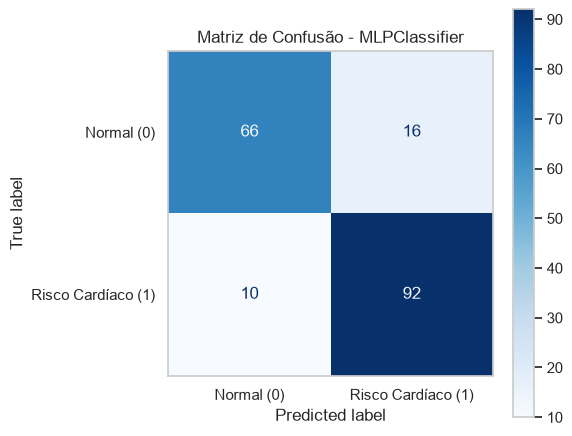

In [4]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    matthews_corrcoef,
)

y_pred = pipeline_mlp.predict(X_test)

acuracia = accuracy_score(y_test, y_pred)
mcc = matthews_corrcoef(y_test, y_pred)

print(f'Acurácia Global no Conjunto de Teste: {acuracia:.4f} ({acuracia * 100:.2f}%)')
print(f'Matthews Correlation Coefficient (MCC): {mcc:.4f}')
print('\nRelatório Detalhado de Métricas por Classe:')
print(classification_report(y_test, y_pred, target_names=['Normal (0)', 'Risco Cardíaco (1)']))

cm = confusion_matrix(y_test, y_pred)
fig, ax = plt.subplots(figsize=(6, 5))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Normal (0)', 'Risco Cardíaco (1)'])
disp.plot(cmap='Blues', ax=ax, values_format='d')
ax.set_title('Matriz de Confusão - MLPClassifier')
plt.grid(False)
plt.tight_layout()
plt.show()

# 5. Exportação do Modelo Treinado

In [5]:
from pathlib import Path
import joblib

caminho_modelo = Path('../models/pipeline_rede_neural.joblib')
caminho_modelo.parent.mkdir(parents=True, exist_ok=True)

joblib.dump(pipeline_mlp, caminho_modelo)
print(f'Pipeline completo serializado com sucesso em: {caminho_modelo.resolve()}')

# Teste rápido de recarregamento e inferência
modelo_carregado = joblib.load(caminho_modelo)
amostra_teste = X_test.iloc[[0]]
pred_classe = modelo_carregado.predict(amostra_teste)[0]
pred_proba = modelo_carregado.predict_proba(amostra_teste)[0]
print(f'Teste de verificação -> Classe: {pred_classe} | Probabilidades: {np.round(pred_proba, 4)}')

Pipeline completo serializado com sucesso em: C:\Users\jpgru\Downloads\atv2-redes-neurais-mlp\am-at2-redes-neurais\models\pipeline_rede_neural.joblib
Teste de verificação -> Classe: 1 | Probabilidades: [0.0681 0.9319]
